In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

# 載入加州房價資料
housing = fetch_california_housing()

# X：輸入特徵
X = housing.data

# y：預測的目標值（房屋中位數價格）
y = housing.target

# 印出資料集大小
print("資料筆數：", X.shape[0])
print("特徵數量：", X.shape[1])
print("特徵名稱：", housing.feature_names)

# 將資料切分為訓練集與測試集
# test_size=0.2：20% 用於測試，80% 用於訓練
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\n訓練資料筆數：", X_train.shape[0])
print("測試資料筆數：", X_test.shape[0])

資料筆數： 20640
特徵數量： 8
特徵名稱： ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

訓練資料筆數： 16512
測試資料筆數： 4128


In [ ]:
import pandas as pd
# California Housing：EDA 資料檢查
# 查看資料基本統計
print("=== 基本統計資訊 ===")
display(pd.DataFrame(X, columns=housing.feature_names).describe().round(3))

# 檢查缺失值
print("\n=== 缺失值檢查 ===")
print(pd.DataFrame(X, columns=housing.feature_names).isnull().sum())

# 檢查目標值統計
print("\n=== 房價目標值統計 ===")
print(pd.Series(y, name="House Price").describe().round(3))

# 查看特徵與目標值的相關性
eda_df = pd.DataFrame(X, columns=housing.feature_names)
eda_df["Target"] = y

print("\n=== 特徵相關係數 ===")
display(
    eda_df.corr()["Target"]
    .sort_values(ascending=False)
    .round(3)
)


=== 基本統計資訊 ===


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000,20640.000
mean,3.871,28.639,5.429,1.097,1425.477,3.071,35.632,-119.570
std,1.900,12.586,2.474,0.474,1132.462,10.386,2.136,2.004
min,0.500,1.000,0.846,0.333,3.000,0.692,32.540,-124.350
25%,2.563,18.000,4.441,1.006,787.000,2.430,33.930,-121.800
50%,3.535,29.000,5.229,1.049,1166.000,2.818,34.260,-118.490
75%,4.743,37.000,6.052,1.100,1725.000,3.282,37.710,-118.010
max,15.000,52.000,141.909,34.067,35682.000,1243.333,41.950,-114.310



=== 缺失值檢查 ===
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

=== 房價目標值統計 ===
count    20640.000
mean         2.069
std          1.154
min          0.150
25%          1.196
50%          1.797
75%          2.647
max          5.000
Name: House Price, dtype: float64

=== 特徵相關係數 ===


,Target
Target,1.000
MedInc,0.688
AveRooms,0.152
HouseAge,0.106
AveOccup,-0.024
Population,-0.025
Longitude,-0.046
AveBedrms,-0.047
Latitude,-0.144


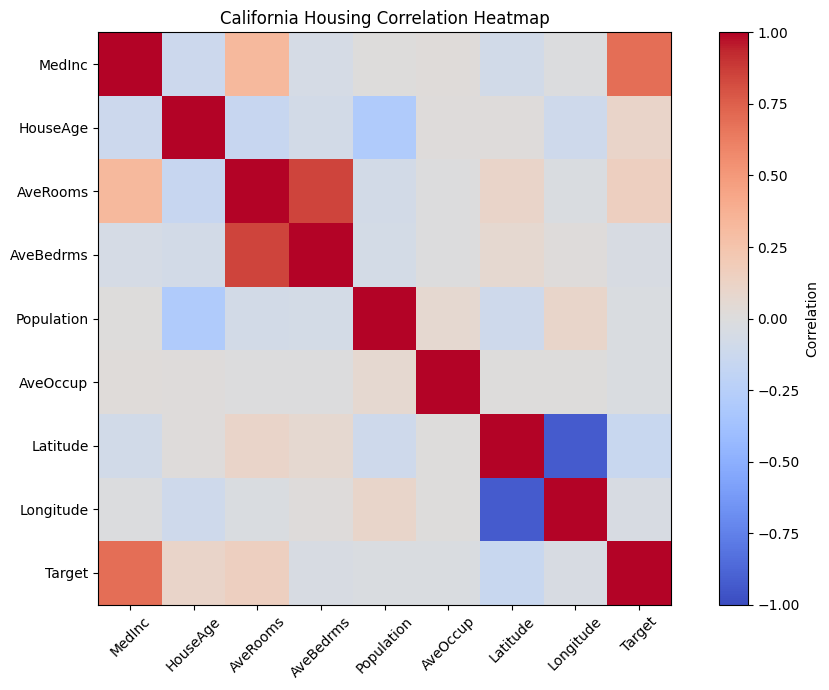

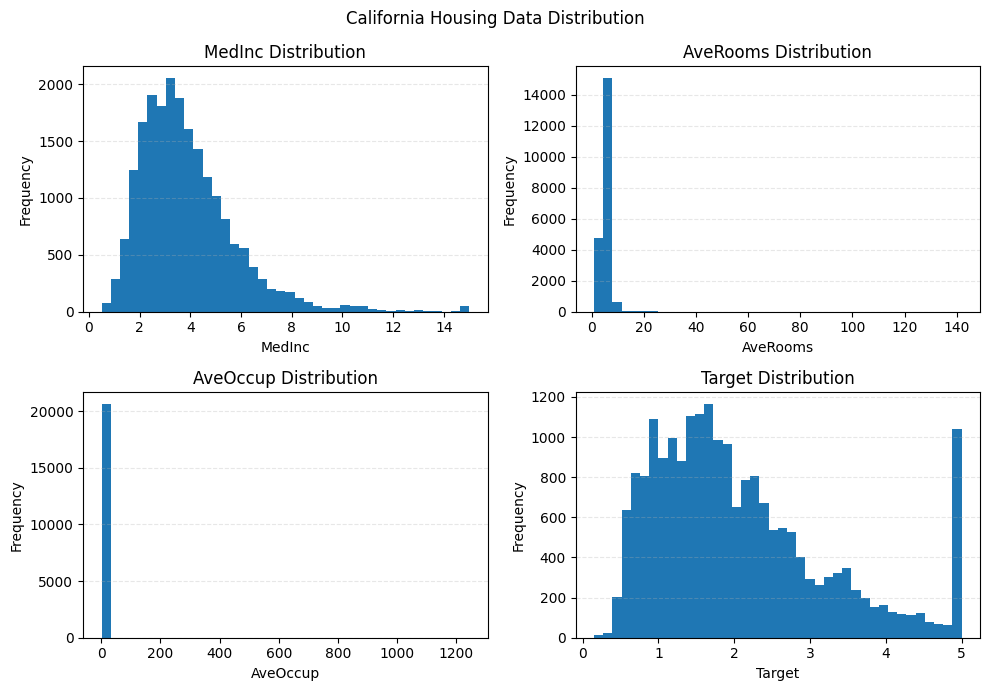

In [ ]:

# California Housing：EDA 視覺化
# 建立 EDA 資料表
eda_df = pd.DataFrame(X, columns=housing.feature_names)
eda_df["Target"] = y

# 繪製相關性熱圖
corr_matrix = eda_df.corr()

plt.figure(figsize=(10, 7))

plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=45
)
plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("California Housing Correlation Heatmap")
plt.tight_layout()
plt.show()


# 繪製重要特徵的資料分布
features = ["MedInc", "AveRooms", "AveOccup", "Target"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, feature in zip(axes.flatten(), features):
    ax.hist(eda_df[feature], bins=40)
    ax.set_title(f"{feature} Distribution")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.suptitle("California Housing Data Distribution")
plt.tight_layout()
plt.show()



=== 三種回歸模型：5-Fold K-Fold 比較表 ===


,Model,MSE,MAE,RMSE,R_square
0,Gradient Boosting,0.2833,0.3698,0.5321,0.7881
1,Linear Regression,0.5193,0.5291,0.7205,0.6115
2,Decision Tree,0.5225,0.5266,0.7228,0.6091



=== 各項指標最佳模型 ===
MSE 最低：Gradient Boosting
MAE 最低：Gradient Boosting
RMSE 最低：Gradient Boosting
R² 最高：Gradient Boosting


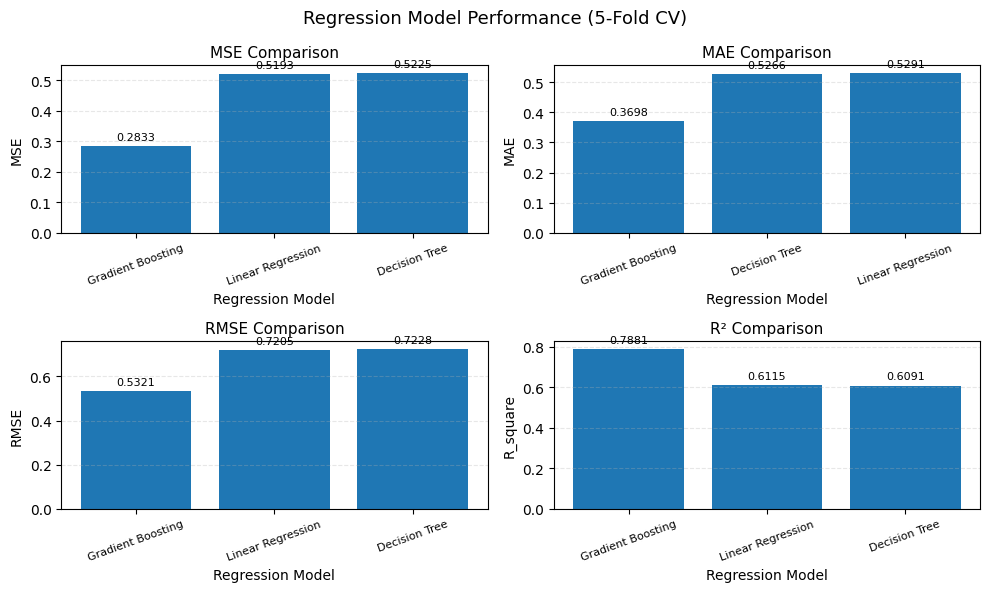


=== 5-Fold K-Fold 初步比較分析 ===
1. MSE：Gradient Boosting 的平均平方誤差最低。
2. MAE：Gradient Boosting 的平均絕對誤差最低。
3. RMSE：Gradient Boosting 的平均均方根誤差最低。
4. R²：Gradient Boosting 的平均決定係數最高。


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor

# 建立三種原始回歸模型
cv_models = {
    "Linear Regression": LinearRegression(),

    # max_depth=5：限制決策樹最多五層，避免樹過度複雜
    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ),

    # n_estimators=100：建立 100 個提升階段
    # learning_rate=0.1：控制每個階段的學習幅度
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# 建立 5-Fold K-Fold 交叉驗證

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 設定四項評估指標
scoring = {
    "MSE": "neg_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# 執行交叉驗證
cv_results = []

for name, model in cv_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=kfold,
        scoring=scoring,
        n_jobs=-1
    )

    # 計算五折平均結果
    cv_results.append({
        "Model": name,
        "MSE": -scores["test_MSE"].mean(),
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R_square": scores["test_R2"].mean()
    })

# 5顯示完整比較表

cv_table = pd.DataFrame(cv_results)

print("\n=== 三種回歸模型：5-Fold K-Fold 比較表 ===")

display(
    cv_table
    .sort_values(by="RMSE")
    .round(4)
    .reset_index(drop=True)
)

# 6. 找出各項指標最佳模型
best_mse = cv_table.loc[cv_table["MSE"].idxmin()]
best_mae = cv_table.loc[cv_table["MAE"].idxmin()]
best_rmse = cv_table.loc[cv_table["RMSE"].idxmin()]
best_r2 = cv_table.loc[cv_table["R_square"].idxmax()]
print("\n=== 各項指標最佳模型 ===")
print(f"MSE 最低：{best_mse['Model']}")
print(f"MAE 最低：{best_mae['Model']}")
print(f"RMSE 最低：{best_rmse['Model']}")
print(f"R² 最高：{best_r2['Model']}")

# 繪製四項評估指標比較圖
metrics = [
    ("MSE", "MSE Comparison"),
    ("MAE", "MAE Comparison"),
    ("RMSE", "RMSE Comparison"),
    ("R_square", "R² Comparison")
]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for ax, (metric, title) in zip(axes.flatten(), metrics):

    # 依照指標數值排序
    plot_data = cv_table.sort_values(
        by=metric,
        ascending=(metric != "R_square")
    )

    bars = ax.bar(
        plot_data["Model"],
        plot_data[metric]
    )

    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Regression Model")
    ax.set_ylabel(metric)

    ax.tick_params(axis="x", rotation=20, labelsize=8)

    # 標示數值
    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=3,
        fontsize=8
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

plt.suptitle(
    "Regression Model Performance (5-Fold CV)",
    fontsize=13
)
plt.tight_layout()
plt.show()
print("\n=== 5-Fold K-Fold 初步比較分析 ===")
print(
    f"1. MSE：{best_mse['Model']} 的平均平方誤差最低。"
)
print(
    f"2. MAE：{best_mae['Model']} 的平均絕對誤差最低。"
)
print(
    f"3. RMSE：{best_rmse['Model']} 的平均均方根誤差最低。"
)
print(
    f"4. R²：{best_r2['Model']} 的平均決定係數最高。"
)

In [ ]:
from sklearn.model_selection import GridSearchCV

# 設定三個模型與超參數搜尋範圍
search_settings = {
    "Linear Regression": {
        "model": LinearRegression(),
        "params": {
            "fit_intercept": [True, False]
        }
    },

    "Decision Tree": {
        "model": DecisionTreeRegressor(random_state=42),
        "params": {
            "max_depth": [3, 5, 10, None],
            "min_samples_split": [2, 5, 10]
        }
    },

    "Gradient Boosting": {
        "model": GradientBoostingRegressor(random_state=42),
        "params": {
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1],
            "max_depth": [2, 3]
        }
    }
}

# 設定四項評估指標
scoring = {
    "MSE": "neg_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R_square": "r2"
}

# 執行 GridSearchCV 超參數調校
tuned_models = {}
tuning_results = []

for name, settings in search_settings.items():

    print(f"\n正在調校模型：{name}")

    search = GridSearchCV(
        estimator=settings["model"],
        param_grid=settings["params"],
        scoring=scoring,
        refit="RMSE",
        cv=kfold,
        n_jobs=-1,
        return_train_score=False
    )

    # 使用訓練資料進行 5 折交叉驗證與參數搜尋
    search.fit(X_train, y_train)

    # 儲存最佳模型
    tuned_models[name] = search.best_estimator_

    # 找出最佳參數組合所對應的交叉驗證結果
    best_index = search.best_index_
    results = search.cv_results_

    tuning_results.append({
        "Model": name,
        "Best Parameters": search.best_params_,
        "CV_MSE": -results["mean_test_MSE"][best_index],
        "CV_MAE": -results["mean_test_MAE"][best_index],
        "CV_RMSE": -results["mean_test_RMSE"][best_index],
        "CV_R2": results["mean_test_R_square"][best_index]
    })

    print("最佳參數：", search.best_params_)
    print(f"最佳 CV RMSE：{-search.best_score_:.4f}")

# 顯示超參數調校結果
tuned_table = pd.DataFrame(tuning_results)

print("\n=== 超參數調校結果（5-Fold GridSearchCV）===")

display(
    tuned_table
    .sort_values(by="CV_RMSE")
    .round(4)
    .reset_index(drop=True)
)



正在調校模型：Linear Regression
最佳參數： {'fit_intercept': True}
最佳 CV RMSE：0.7205

正在調校模型：Decision Tree
最佳參數： {'max_depth': 10, 'min_samples_split': 10}
最佳 CV RMSE：0.6434

正在調校模型：Gradient Boosting
最佳參數： {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
最佳 CV RMSE：0.5047

=== 超參數調校結果（5-Fold GridSearchCV）===


,Model,Best Parameters,CV_MSE,CV_MAE,CV_RMSE,CV_R2
0,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.2548,0.3478,0.5047,0.8094
1,Decision Tree,"{'max_depth': 10, 'min_samples_split': 10}",0.4142,0.4312,0.6434,0.6901
2,Linear Regression,{'fit_intercept': True},0.5193,0.5291,0.7205,0.6115


In [ ]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
import pandas as pd

# 建立模擬回歸資料集
X, y = make_regression(
    n_samples=1000,
    n_features=5,
    n_informative=4,
    noise=10,
    random_state=42
)

# 檢查資料集
print("=== make_regression 模擬資料集 ===")
print("資料特徵形狀：", X.shape)
print("目標資料形狀：", y.shape)

print("\n=== 前五筆特徵資料 ===")
display(pd.DataFrame(
    X[:5],
    columns=[f"Feature_{i+1}" for i in range(X.shape[1])]
))

print("\n=== 前五筆目標資料 ===")
print(y[:5])

# 切分訓練集與測試集
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\n=== 資料切分結果 ===")
print("訓練集特徵：", X_train.shape)
print("測試集特徵：", X_test.shape)
print("訓練集目標：", y_train.shape)
print("測試集目標：", y_test.shape)

=== make_regression 模擬資料集 ===
資料特徵形狀： (1000, 5)
目標資料形狀： (1000,)

=== 前五筆特徵資料 ===


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5
0,-0.457096,-0.027515,1.772252,-0.602212,1.661259
1,0.473407,-1.188963,-0.049880,0.290947,-1.046121
2,-0.003374,0.778361,-0.551186,-0.170185,-0.818199
3,0.984322,0.234215,1.550500,-0.213989,-0.998354
4,-0.922410,-0.238932,-0.366824,1.615376,-0.391758



=== 前五筆目標資料 ===
[ 88.59785077 -54.227508   -37.73907364   2.83766668 -58.91436771]

=== 資料切分結果 ===
訓練集特徵： (800, 5)
測試集特徵： (200, 5)
訓練集目標： (800,)
測試集目標： (200,)


In [ ]:
# 將特徵資料轉換成 DataFrame
eda_df = pd.DataFrame(X, columns=[
    "Feature_1", "Feature_2", "Feature_3",
    "Feature_4", "Feature_5"
])

# 查看特徵基本統計資訊
print("=== 特徵基本統計資訊 ===")
display(eda_df.describe().round(3))

# 檢查缺失值
print("=== 缺失值檢查 ===")
print(eda_df.isnull().sum())

# 查看目標變數統計資訊
print("=== 目標變數統計資訊 ===")
print(pd.Series(y, name="Target").describe().round(3))

# 查看特徵與目標變數的相關性
eda_df["Target"] = y
print("=== 特徵與目標變數相關性 ===")
display(eda_df.corr()["Target"].sort_values(ascending=False).round(3))


=== 特徵基本統計資訊 ===


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5
count,1000.000,1000.000,1000.000,1000.000,1000.000
mean,0.007,0.001,-0.017,0.033,0.005
std,0.960,0.999,1.029,0.989,1.005
min,-3.008,-3.170,-2.940,-3.177,-3.241
25%,-0.650,-0.646,-0.712,-0.608,-0.694
50%,0.065,0.028,-0.034,-0.007,0.022
75%,0.679,0.649,0.664,0.691,0.642
max,3.079,3.926,3.243,3.853,3.152


=== 缺失值檢查 ===
Feature_1    0
Feature_2    0
Feature_3    0
Feature_4    0
Feature_5    0
dtype: int64
=== 目標變數統計資訊 ===
count    1000.000
mean       -0.378
std        61.435
min      -188.287
25%       -42.216
50%         1.071
75%        40.893
max       173.756
Name: Target, dtype: float64
=== 特徵與目標變數相關性 ===


,Target
Target,1.000
Feature_5,0.782
Feature_1,0.436
Feature_2,0.307
Feature_3,0.294
Feature_4,0.001


In [ ]:
from sklearn.model_selection import KFold, cross_validate

cv_models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# 建立 5-Fold K-Fold
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 設定四項評估指標
scoring = {
    "MSE": "neg_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# 執行交叉驗證
cv_results = []

for name, model in cv_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=kfold,
        scoring=scoring,
        n_jobs=-1
    )

    # 計算五折平均評估結果
    cv_results.append({
        "Model": name,
        "MSE": -scores["test_MSE"].mean(),
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R_square": scores["test_R2"].mean()
    })

# 6. 顯示比較結果
cv_table = pd.DataFrame(cv_results)

print("\n=== make_regression 三種回歸模型：5-Fold K-Fold 比較表 ===")

display(
    cv_table
    .sort_values(by="RMSE")
    .round(4)
    .reset_index(drop=True)
)



=== make_regression 三種回歸模型：5-Fold K-Fold 比較表 ===


,Model,MSE,MAE,RMSE,R_square
0,Linear Regression,104.5232,8.0875,10.2182,0.9706
1,Gradient Boosting,205.5559,11.1486,14.3029,0.9427
2,Decision Tree,955.8603,24.6733,30.8416,0.7301


In [ ]:
make_search_settings = {
    "Linear Regression": {
        "model": LinearRegression(),
        "params": {
            "fit_intercept": [True, False]
        }
    },

    "Decision Tree": {
        "model": DecisionTreeRegressor(random_state=42),
        "params": {
            "max_depth": [3, 5, 10, None],
            "min_samples_split": [2, 5, 10]
        }
    },

    "Gradient Boosting": {
        "model": GradientBoostingRegressor(random_state=42),
        "params": {
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1],
            "max_depth": [2, 3]
        }
    }
}

# 儲存調校結果
make_tuning_results = []

# 依序調校三種模型
for name, settings in make_search_settings.items():

    # 建立 GridSearchCV
    search = GridSearchCV(
        estimator=settings["model"],
        param_grid=settings["params"],
        scoring=scoring,
        refit="RMSE",
        cv=kfold,
        n_jobs=-1,
        return_train_score=False
    )

    # 使用模擬資料進行超參數調校
    search.fit(X_train, y_train)

    # 取得最佳參數組合的位置
    best_index = search.best_index_
    results = search.cv_results_

    # 整理最佳參數與四項評估指標
    make_tuning_results.append({
        "Model": name,
        "Best Parameters": search.best_params_,
        "CV_MSE": -results["mean_test_MSE"][best_index],
        "CV_MAE": -results["mean_test_MAE"][best_index],
        "CV_RMSE": -results["mean_test_RMSE"][best_index],
        "CV_R_square": results["mean_test_R2"][best_index]
    })

make_tuned_table = pd.DataFrame(make_tuning_results)
display(make_tuned_table)

,Model,Best Parameters,CV_MSE,CV_MAE,CV_RMSE,CV_R_square
0,Linear Regression,{'fit_intercept': False},104.222905,8.072846,10.202426,0.970639
1,Decision Tree,"{'max_depth': 10, 'min_samples_split': 10}",740.076525,21.315190,27.184995,0.791277
2,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",171.201616,10.189818,13.075004,0.951881
